In [41]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 2/9/2022
# version ='1.0'

# Demo: Solving Convex-Concave Game via Infeasible Start Newton Method

In the text book book-convex-2004, section 10.3, the infeasible start Newton method was used to solve convex-concave games. As an example of convex-concave game defined on $u\in R^n, v\in R^m$ with the payoff function,
$$
f(u,v) = u^TAv+b^Tu+c^Tv-\log(1-u^Tu)+\log(1-v^Tv)
$$
The first player, $u$, wants to minimize the payoff by $$\displaystyle{\inf_u\sup_v f(u,v)}$$
The second player, $v$, wants to maximize the payoff by $$\displaystyle{\sup_v\inf_u f(u,v)}$$

$(u^*, v^*)$ is the solution of the game, or a \textbf{saddle-point} for the game, if for all $u, v$,
$$
f(u^*, v) \leq f(u^*, v^*) \leq f(u, v^*)
$$
i.e. $(u^*, v^*)$ is characterized by 
$$
\nabla f(u^*, v^*) = 0
$$ 
By using the infeasible start Newton method, the residual is
$$
r(u,v)=\nabla f(u,v)=\left[\begin{array}{c}
\nabla_u f(u, v) \\
\nabla_v f(u, v) \\
\end{array}  \right] = \left[\begin{array}{c}
Av + b + \frac{2u}{1-u^Tu}\\
A^Tu+c-\frac{2v}{1-v^Tv} \\
\end{array} \right]
$$
The hessian is

$$
\nabla^2 f(u,v)=\left[\begin{array}{cc}
\nabla_{uu}f(u,v) & \nabla_{uv}f(u,v)\\
\nabla_{vu}f(u,v) & \nabla_{vv}f(u,v)\\
\end{array} \right]=\left[\begin{array}{cc}
\frac{2I}{1-u^Tu} + \frac{4uu^T}{1-u^Tu} & A\\
A^T & \frac{-2I}{1-v^Tv}-\frac{4vv^T}{1-v^Tv}\\
\end{array} \right]
$$

Thus, the Newton step is calculated by

$$
\left[\begin{array}{c}
\Delta u \\
\Delta v \\
\end{array} \right] = -\left[\nabla^2 f(u,v)\right]^{-1} r(u,v) 
$$

In [42]:
import numpy as np
import sys
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

The payoff function, $f(u,v)=u^TAv+b^Tu + c^Tv - \log(1-u^Tu) + \log(1-v^Tv)$

it requires $u^Tu < 1$ and $v^Tv < 1$

$\nabla f(u,v)_u=Av + b + \frac{2u}{1-u^Tu}$

$\nabla f(u,v)_v=A^Tu+c-\frac{2v}{1-v^Tv}$

$\nabla^2 f(u,v)=\left[\begin{array}{cc}
                            \nabla_{uu}f(u,v) & \nabla_{uv}f(u,v)\\
                            \nabla_{vu}f(u,v) & \nabla_{vv}f(u,v)\\
                        \end{array} \right]
                    =\left[\begin{array}{cc}
                        \frac{2I}{1-u^Tu} + \frac{4uu^T}{1-u^Tu} & A\\
                        A^T & \frac{-2I}{1-v^Tv}-\frac{4vv^T}{1-v^Tv}\\
                          \end{array}
                     \right]$

In [43]:
def my_f(u, v, A, b, c):
    """
    The payoff function, $f(u,v)=u^TAv+b^Tu + c^Tv - \log(1-u^Tu) + \log(1-v^Tv) $
    :param u:
    :param v:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return u.T @ A @ v + b.T @ u + c.T @ v - np.log(1 - (u.T @ u).item()) + np.log(1 - (v.T @ v).item())


def my_f_feasible(u, v):
    """
    it requires $u^Tu < 1$ and $v^Tv < 1$
    :param u:
    :param v:
    :return:
    """
    return (u.T @ u).item() < 1 and (v.T @ v).item() < 1


def my_gradient_f_u(u, v, A, b, c):
    """
    $\nabla f(u,v)_u=Av + b + \frac{2u}{1-u^Tu}$
    :param u:
    :param v:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return A @ v + b + 2 * u / (1 - (u.T @ u).item())


def my_gradient_f_v(u, v, A, b, c):
    """
    $\nabla f(u,v)_v=A^Tu+c-\frac{2v}{1-v^Tv}$
    :param u:
    :param v:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return A.T @ u + c - 2 * v / (1 - (v.T @ v).item())


def my_hessian(u, v, A, b, c):
    """
    $ \nabla^2 f(u,v)=\left[\begin{array}{cc}
                            \nabla_{uu}f(u,v) & \nabla_{uv}f(u,v)\\
                            \nabla_{vu}f(u,v) & \nabla_{vv}f(u,v)\\
                        \end{array} \right]
                    =\left[\begin{array}{cc}
                        \frac{2I}{1-u^Tu} + \frac{4uu^T}{1-u^Tu} & A\\
                        A^T & \frac{-2I}{1-v^Tv}-\frac{4vv^T}{1-v^Tv}\\
                          \end{array}
                     \right] $
    :param u:
    :param v:
    :param A:
    :param b:
    :param c:
    :return:
    """
    n_u = len(u)
    n_v = len(v)
    uTu = (u.T @ u).item()
    vTv = (v.T @ v).item()
    d_uu = 2 / (1 - uTu) * np.identity(n_u) + 4 / ((1 - uTu) ** 2) * (u @ u.T)
    d_vv = -2 / (1 - vTv) * np.identity(n_v) - 4 / ((1 - vTv) ** 2) * (v @ v.T)
    d_uv = A
    d_vu = A.T
    return np.block([[d_uu, d_uv], [d_vu, d_vv]])


$r(u,v)=\nabla f(u,v)=\left[\begin{array}{c}
                            \nabla_u f(u, v) \\
                            \nabla_v f(u, v) \\
                           \end{array}
                        \right]$
                        
 $|r|=\parallel \left[\begin{array}{c} r_{dual} \\ r_{pri}\\ \end{array} \right] \parallel _2$
 

In [44]:
def my_residual(u, v, A, b, c):
    """
    $r(u,v)=\nabla f(u,v)=\left[\begin{array}{c}
                            \nabla_u f(u, v) \\
                            \nabla_v f(u, v) \\
                           \end{array}
                        \right]$
    :param u:
    :param v:
    :param A:
    :param b:
    :param c:
    :return:
    """
    du = my_gradient_f_u(u, v, A, b, c)
    dv = my_gradient_f_v(u, v, A, b, c)
    return np.block([[du], [dv]])


def residual_norm_f(u, v, args):
    """
    $|r|=\parallel \left[\begin{array}{c} r_{dual} \\ r_{pri}\\ \end{array} \right] \parallel _2
    $
    :param u:
    :param v:
    :param args:
    :return:
    """
    r = my_residual(u, v, *args)
    return np.linalg.norm(r)


def residula_norm_u_v(u, v, args):
    """
    $|r_u|, |r_v|$
    :param u:
    :param v:
    :param args:
    :return:
    """
    r = my_residual(u, v, *args)
    ru = r[0: len(u)]
    rv = r[len(u):]
    return np.linalg.norm(ru), np.linalg.norm(rv)

 The Newton step is calculated by
    $$
        \left[\begin{array}{c}
                \Delta u \\
                \Delta v \\
        \end{array} \right] = -\left[\nabla^2 f(u,v)\right]^{-1} r(u,v)
    $$

In [45]:
def newton_step(u, v, args):
    """
    The Newton step is calculated by
    $$
        \left[\begin{array}{c}
                \Delta u \\
                \Delta v \\
        \end{array} \right] = -\left[\nabla^2 f(u,v)\right]^{-1} r(u,v)
    $$
    :param u:
    :param v:
    :param args:
    :return:
    """
    Dr = my_hessian(u, v, *args)
    minus_residual = -1 * np.block([[my_gradient_f_u(u, v, *args)], [my_gradient_f_v(u, v, *args)]])
    if np.linalg.cond(Dr) < 1 / sys.float_info.epsilon:
        x_nt = np.linalg.inv(Dr) @ minus_residual
        u_nt = x_nt[0: len(u)]
        v_nt = x_nt[len(u):]
        return u_nt, v_nt
    else:
        raise RuntimeError(r'Dr (i.e. $\nabla^2 f(x)$) matrix is not invertible.')

Backtracking line search implementation, see to Algorithm 9.2 in the textbook

In [46]:
def backtracking_line_search(u, v, du, dv, alpha, beta, args):
    """
    Backtracking line search implementation, see to Algorithm 9.2 in the textbook
    :param u:
    :param v:
    :param du:
    :param dv:
    :param alpha:
    :param beta:
    :param args:
    :return:
    """
    t = 1
    r = residual_norm_f
    while (not my_f_feasible(u + t * du, v + t * dv)) \
            or r(u + t * du, v + t * dv, args) > (1 - alpha * t) * r(u, v, args):
        t = beta * t
    return t

plot the convergence process in the special case that $n_u=1$, $n_v=1$

In [47]:
def plot_convergence_process_in_2D(seed=1):
    """
    plot the convergence process in the special case that $n_u=1$, $n_v=1$
    :return:
    """
    n_u = 1
    n_v = 1
    np.random.seed(seed)
    A = np.random.uniform(-1, 1, (n_u, n_v))

    # randomly generate the saddle point $(u_p, v_p)$, which must satisfy that $\nabla f(u_p,v_p)=0$
    scale = 0.1
    u_asterisk_t = np.random.rand(n_u, 1)
    v_asterisk_t = np.random.rand(n_v, 1)

    u_asterisk = u_asterisk_t / np.linalg.norm(u_asterisk_t) * scale
    v_asterisk = v_asterisk_t / np.linalg.norm(v_asterisk_t) * scale

    b = -2 * u_asterisk / (1 - (u_asterisk.T @ u_asterisk).item()) - A @ v_asterisk
    c = +2 * v_asterisk / (1 - (v_asterisk.T @ v_asterisk).item()) - A.T @ u_asterisk

    args = (A, b, c)

    # to plot the contour of the payoff function
    delta = 0.01
    min_u = -1 + delta
    max_u = 1 - delta
    min_v = -1 + delta
    max_v = 1 - delta

    u = np.arange(min_u, max_u, delta)
    v = np.arange(min_v, max_v, delta)
    U, V = np.meshgrid(u, v)
    Z = np.zeros(U.shape)

    for u_i in range(len(u)):
        for v_i in range(len(v)):
            u1 = u[u_i]
            v1 = v[v_i]
            Z[v_i][u_i] = my_f(np.array([[u1]]), np.array([[v1]]), *args)

    ax = plt.subplot(1, 1, 1)
    CS = ax.contour(U, V, Z, linestyles='dashed',
                    levels=[-3, -2, -1.5, -1, -.5, -.25, -.1, -.05, 0, 0.05, 0.1, 0.25, 0.5, 1, 1.5, 2,  3],
                    vmin=-0.5, vmax=0.5)
    ax.clabel(CS, fontsize=6, inline=True)
    ax.set_aspect('equal', adjustable='box')

    alpha = 0.01
    beta = 0.5

    epsilon_u = 1e-12
    epsilon_v = 1e-12
    max_iter = 100

    # initialization of start point randomly
    delta_u = 0.9
    delta_v = 0.8
    u0 = np.zeros([n_u, 1]) + np.random.sample() * delta_u
    v0 = np.zeros([n_v, 1]) + np.random.sample() * delta_v

    iteration = 0
    u = u0
    v = v0
    ru_norm, rv_norm = residula_norm_u_v(u, v, args)

    # log the statistics
    du = [ru_norm]
    dv = [rv_norm]
    fuv = [my_f(u, v, *args).item()]
    u_points = []
    v_points = []
    u_points.append(u.item())
    v_points.append(v.item())

    # The infeasible start Newton method to solve the convex-concave game
    while True:
        # print('DBG: f(u, v)={}'.format(my_f(u, v, *args)))
        u_nt, v_nt = newton_step(u, v, args)
        t = backtracking_line_search(u, v, u_nt, v_nt, alpha, beta, args)
        u = u + t * u_nt
        v = v + t * v_nt

        ru_norm, rv_norm = residula_norm_u_v(u, v, args)

        # log the statistics
        u_points.append(u.item())
        v_points.append(v.item())
        du.append(ru_norm)
        dv.append(rv_norm)
        fuv.append(my_f(u, v, *args).item())

        if ru_norm <= epsilon_u and rv_norm <= epsilon_v:
            break

        iteration += 1
        if iteration >= max_iter:
            break

    ru_norm, rv_norm = residula_norm_u_v(u, v, args)
    fuv.append(my_f(u, v, *args).item())
    du.append(ru_norm)
    dv.append(rv_norm)

    diff_u = np.max((u - u_asterisk) ** 2)
    diff_v = np.max((v - v_asterisk) ** 2)

    print('Info: uTu = {}, vTv = {}'.format(u.T @ u, v.T @ v))
    print('Info: diff of (u, v) to the optimal point = {}, {}'.format(diff_u, diff_v))

    for i in range(len(u_points) - 1):
        ax.annotate("", xy=(u_points[i+1], v_points[i+1]), xytext=(u_points[i], v_points[i]), arrowprops=dict(arrowstyle="->"))
    ax.plot(u_points, v_points, marker='+', label=r'$(u_t, v_t)$', color='black')
    ax.legend()
    ax.grid()
    ax.set_xlabel('u')
    ax.set_ylabel('v')
    ax.set_title('f(u,v)')
    plt.show()

solve the convex-concav game by the infeasible start Newton start method
    plot the metrics captured during the convergence of the convex concave game

In [48]:
def plot_convergence_convex_concave_game(n_u, n_v, seed=1):
    """
    solve the convex-concav game by the infeasible start Newton start method
    plot the metrics captured during the convergence of the convex concave game
    :param n_u:
    :param n_v:
    :param seed:
    :return:
    """
    np.random.seed(seed)
    A = np.random.rand(n_u, n_v)

    # randomly generate the saddle point $(u_p, v_p)$, which must satisfy that $\nabla f(u_p,v_p)=0$
    scaler = 0.1
    u_asterisk_t = np.random.rand(n_u, 1)
    v_asterisk_t = np.random.rand(n_v, 1)
    u_asterisk = u_asterisk_t / np.linalg.norm(u_asterisk_t) * scaler
    v_asterisk = v_asterisk_t / np.linalg.norm(v_asterisk_t) * scaler
    b = -2 * u_asterisk / (1 - (u_asterisk.T @ u_asterisk).item()) - A @ v_asterisk
    c = +2 * v_asterisk / (1 - (v_asterisk.T @ v_asterisk).item()) - A.T @ u_asterisk
    args = (A, b, c)

    alpha = 0.01
    beta = 0.5
    epsilon_u = 1e-12
    epsilon_v = 1e-12
    max_iter = 100

    # initialization of starting point
    delta_u = 0.01
    delta_v = -0.02
    u0 = np.zeros([n_u, 1]) + np.random.sample() * delta_u
    v0 = np.zeros([n_v, 1]) + np.random.sample() * delta_v

    iteration = 0
    u = u0
    v = v0
    ru_norm, rv_norm = residula_norm_u_v(u, v, args)
    du = [ru_norm]
    dv = [rv_norm]
    fuv = [my_f(u, v, *args).item()]

    # The infeasible start Newton method to solve the convex-concave game
    while True:
        print('DBG: iteration={}, f(u, v)={}'.format(iteration, my_f(u, v, *args)))
        u_nt, v_nt = newton_step(u, v, args)
        t = backtracking_line_search(u, v, u_nt, v_nt, alpha, beta, args)
        u = u + t * u_nt
        v = v + t * v_nt
        ru_norm, rv_norm = residula_norm_u_v(u, v, args)

        # log the statistics
        du.append(ru_norm)
        dv.append(rv_norm)
        fuv.append(my_f(u, v, *args).item())

        if ru_norm <= epsilon_u and rv_norm <= epsilon_v:
            break

        iteration += 1
        if iteration >= max_iter:
            break

    ru_norm, rv_norm = residula_norm_u_v(u, v, args)
    du.append(ru_norm)
    dv.append(rv_norm)
    fuv.append(my_f(u, v, *args).item())

    plt.figure(figsize=(12, 4))
    ax = plt.subplot(1, 2, 1)
    fuv_a = np.array(fuv)
    ax.plot(fuv_a, marker='+', label='f(u,v)')
    ax.legend()
    ax.grid()
    ax.set_xlabel('iteration')
    ax.set_ylabel('f(u,v)')
    ax.xaxis.set_major_locator(MultipleLocator(1))

    ax = plt.subplot(1, 2, 2)
    ax.semilogy(du, marker='+', linestyle='dashed', fillstyle='none', label=r'$|\nabla_uf(u,v)|$')
    ax.semilogy(dv, marker='o', linestyle='dashed', fillstyle='none', label=r'$|\nabla_vf(u,v)|$')
    ax.legend()
    ax.grid()
    ax.set_xlabel('iteration')
    ax.set_ylabel(r'$|\nabla_uf(u,v)|, |\nabla_vf(u,v)|$')
    ax.xaxis.set_major_locator(MultipleLocator(1))
    plt.show()

Info: uTu = [[0.01]], vTv = [[0.01]]
Info: diff of (u, v) to the optimal point = 1.925929944387236e-34, 1.925929944387236e-34


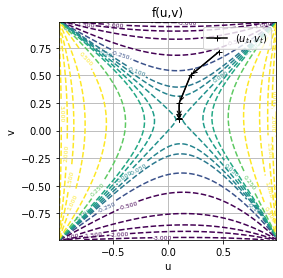

In [49]:
if __name__ == "__main__":
    plot_convergence_process_in_2D(seed=3)

DBG: iteration=0, f(u, v)=[[-13.35873539]]
DBG: iteration=1, f(u, v)=[[-3.72912908]]
DBG: iteration=2, f(u, v)=[[-3.72912583]]


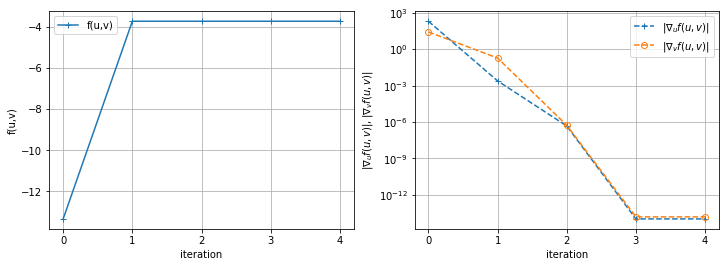

In [50]:
if __name__ == "__main__":
    plot_convergence_convex_concave_game(n_u=1000, n_v=1000, seed=3)